# Гибридная рекомендательная система фильмов (MovieLens ml-latest)

**Задание к теме «Гибридные рекомендательные системы»** · Нетология, курс «Рекомендательные системы»
**Автор:** Александра Бужор (Alexandra Bujor) · Telegram: [@Angry_C_F_O](https://t.me/Angry_C_F_O)

## Задание
1. Датасет ml-latest.
2. Вспомнить подходы, которые мы разбирали.
3. Выбрать понравившийся подход к гибридным системам.
4. Написать свою.

## Какие подходы разбирали на лекции
| Подход из лекции | Как устроен | Ограничение |
|---|---|---|
| **LightFM** (`lecture-5-part-2`) | матричная факторизация, в которой эмбеддинг фильма = сумма эмбеддингов его признаков; WARP-loss | один «чёрный ящик», признаки смешиваются только линейно |
| **Каскад «контент → коллаборатив»** (`hybrid_rec`) | берём последний фильм пользователя, ищем 20 похожих по жанрам (TF-IDF + kNN), переранжируем их предсказанием SVD | кандидатов мало и они зависят от одного фильма; много одинаковых жанровых векторов |

## Какой подход выбран и что сделано своё
Выбран **каскадный (двухэтапный) гибрид** из лекции, но доработанный до схемы, которая используется в продакшене:

1. **Этап 1 — генерация кандидатов из нескольких источников**: коллаборативный PureSVD, контентная модель (жанры + теги + десятилетие выпуска) и популярное. Источники дополняют друг друга: CF находит «похожих по вкусу», контент — новые фильмы без оценок, популярное — подстраховка.
2. **Этап 2 — мета-модель ранжирования** (градиентный бустинг) обучается на *будущих* оценках пользователей и сама решает, как смешивать сигналы: скоры моделей, ранги, предсказанную оценку ALS-MF, статистики фильма и пользователя, жанровые предпочтения. Это гибрид типа **feature combination / meta-level (stacking)**.
3. Для новых пользователей работает **switching-ветка**: взвешенный гибрид с fold-in (без переобучения моделей), а при пустой истории — популярное с байесовским рейтингом по выбранным жанрам.

Все компоненты написаны самостоятельно на `numpy / scipy / scikit-learn` (ALS для матричной факторизации, PureSVD, TF-IDF-профили, ранжировщик), без `surprise` и `lightfm`: так ноутбук ставится одной командой `pip install -r requirements.txt` на Windows, macOS и Linux без компиляторов.

Для честного сравнения реализованы и базовые варианты: популярное, только контент, только коллаборатив, **каскад из лекции** и простой **взвешенный гибрид**.

## 0. Параметры и импорт
По умолчанию используется **ml-latest-small** (та же версия, что в материалах курса, `lecture-1`). Для полной **ml-latest** (~33 млн оценок, 330 тыс. пользователей) поменяйте `DATASET` — данные скачаются автоматически, а `MAX_USERS` ограничит выборку пользователей, чтобы расчёт поместился в память обычного ноутбука. Если в папке полной версии есть `genome-scores.csv`, контентная модель дополнительно использует Tag Genome.

In [1]:
import io
import re
import time
import zipfile
import itertools
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import svds
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, TfidfTransformer
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

DATASET = 'ml-latest-small'   # 'ml-latest-small' или 'ml-latest'
DATA_DIR = Path('data')
MAX_USERS = 10_000            # применяется, только если пользователей больше (актуально для ml-latest)
USE_GENOME = True             # Tag Genome, если файл есть (только в полной ml-latest)

SEED = 42
K = 10                        # длина рекомендательного списка
REL_THRESHOLD = 4.0           # фильм считается «понравившимся», если оценка >= 4
TEST_FRAC = 0.2               # доля последних по времени оценок каждого пользователя в test (и в valid)
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)

pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 60)
np.random.seed(SEED)

## 1. Загрузка данных
Если датасета нет в `data/`, он скачивается с GroupLens; для ml-latest-small есть запасной источник — копия из репозитория курса.

In [2]:
GROUPLENS = 'https://files.grouplens.org/datasets/movielens/{}.zip'
COURSE_MIRROR = 'https://raw.githubusercontent.com/ALKONDR/netology-recsys/master/lecture-1/'


def ensure_dataset(name, data_dir=DATA_DIR):
    target = data_dir / name
    if (target / 'ratings.csv').exists():
        print('Данные найдены:', target)
        return target
    data_dir.mkdir(parents=True, exist_ok=True)
    zip_path = data_dir / f'{name}.zip'
    try:
        print('Скачиваю', GROUPLENS.format(name), '...')
        urllib.request.urlretrieve(GROUPLENS.format(name), zip_path)
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(data_dir)
        zip_path.unlink()
        return target
    except Exception as exc:
        if name != 'ml-latest-small':
            raise RuntimeError(f'Не удалось скачать {name}: {exc}. Скачайте архив вручную '
                               f'и распакуйте в {target}') from exc
        print(f'GroupLens недоступен ({exc}); беру ml-latest-small из материалов курса')
        target.mkdir(parents=True, exist_ok=True)
        for f in ['movies.csv', 'ratings.csv', 'tags.csv', 'links.csv']:
            urllib.request.urlretrieve(COURSE_MIRROR + f, target / f)
        return target


path = ensure_dataset(DATASET)
ratings = pd.read_csv(path / 'ratings.csv',
                      dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int64'})
movies = pd.read_csv(path / 'movies.csv')
tags = pd.read_csv(path / 'tags.csv')
genome = None
if USE_GENOME and (path / 'genome-scores.csv').exists():
    genome = pd.read_csv(path / 'genome-scores.csv',
                         dtype={'movieId': 'int32', 'tagId': 'int32', 'relevance': 'float32'})

n_users_all = ratings['userId'].nunique()
if MAX_USERS and n_users_all > MAX_USERS:
    rng = np.random.default_rng(SEED)
    keep = rng.choice(ratings['userId'].unique(), MAX_USERS, replace=False)
    ratings = ratings[ratings['userId'].isin(keep)].reset_index(drop=True)
    print(f'Случайная выборка {MAX_USERS} пользователей из {n_users_all}')

n_u, n_m = ratings['userId'].nunique(), movies['movieId'].nunique()
print(f'Оценок: {len(ratings):,} | пользователей: {n_u:,} | фильмов в каталоге: {n_m:,} '
      f'| фильмов с оценками: {ratings.movieId.nunique():,} | тегов: {len(tags):,}')
print(f'Заполненность матрицы: {len(ratings) / (n_u * n_m):.4%}')
print('Genome:', 'да' if genome is not None else 'нет')
movies.head()

Данные найдены: data\ml-latest-small
Оценок: 100,836 | пользователей: 610 | фильмов в каталоге: 9,742 | фильмов с оценками: 9,724 | тегов: 3,683
Заполненность матрицы: 1.6968%
Genome: нет


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
per_user = ratings.groupby('userId').size()
per_item = ratings.groupby('movieId').size()
print('Оценок на пользователя: медиана %d, мин %d, макс %d' % (per_user.median(), per_user.min(), per_user.max()))
print('Оценок на фильм: медиана %d; фильмов с 1 оценкой: %.0f%%' % (per_item.median(), 100 * (per_item == 1).mean()))
print('Доля оценок >= %.1f: %.1f%%' % (REL_THRESHOLD, 100 * (ratings.rating >= REL_THRESHOLD).mean()))
ratings['rating'].value_counts().sort_index().to_frame('count').T

Оценок на пользователя: медиана 70, мин 20, макс 2698
Оценок на фильм: медиана 3; фильмов с 1 оценкой: 35%
Доля оценок >= 4.0: 48.2%


rating,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0
count,1370,2811,1791,7551,5550,20047,13136,26818,8551,13211


## 2. Схема валидации
Рекомендации строятся «на будущее», поэтому разбиение **временное по каждому пользователю**: последние 20 % оценок пользователя уходят в `test`, из оставшегося последние 20 % — в `valid`.

| Часть | Для чего |
|---|---|
| `train` | обучение базовых моделей на этапе подбора |
| `valid` | подбор гиперпараметров и **обучение мета-модели** (целевая переменная — понравился ли фильм в будущем) |
| `train_full = train + valid` | переобучение базовых моделей перед финальной проверкой |
| `test` | финальная оценка всех моделей, мета-модель его не видит |

**Релевантный** фильм — оценка в тестовом периоде ≥ 4.0. Просмотренные в train фильмы из рекомендаций исключаются.

Разбиение хронологическое внутри каждого пользователя, но не между пользователями: train одного пользователя может быть позже test другого. Это стандартный компромисс для MovieLens: пользователи активны в разные годы (1996–2018), у большинства вся история укладывается в один день. При глобальном разрезе по дате (80 % оценок до порога) лишь около 5 % пользователей ml-latest-small имели бы оценки по обе стороны, и оценивать было бы почти некого.

**Защита от утечки через теги:** тег, который пользователь поставил фильму, означает, что он этот фильм смотрел. Поэтому теги пар «пользователь–фильм», попавших в valid/test, из контентных признаков удаляются.

In [4]:
class Index:
    # Кодирование userId/movieId в индексы матриц. Каталог — все фильмы movies.csv,
    # поэтому контентная часть может рекомендовать фильмы, у которых ещё нет оценок.
    def __init__(self, movies, ratings):
        self.item_ids = movies['movieId'].values
        self.iid = pd.Series(np.arange(len(self.item_ids)), index=self.item_ids)
        self.user_ids = np.sort(ratings['userId'].unique())
        self.uid = pd.Series(np.arange(len(self.user_ids)), index=self.user_ids)
        self.n_users, self.n_items = len(self.user_ids), len(self.item_ids)

    def encode(self, df):
        out = df.copy()
        out['u'] = self.uid.loc[out['userId'].values].values
        out['i'] = self.iid.loc[out['movieId'].values].values
        return out

    def matrix(self, df, values=None):
        v = np.ones(len(df)) if values is None else values
        return sp.csr_matrix((v, (df['u'].values, df['i'].values)), shape=(self.n_users, self.n_items))


def temporal_split(df, test_frac=TEST_FRAC):
    df = df.sort_values(['userId', 'timestamp', 'movieId'], kind='mergesort')
    rank = df.groupby('userId').cumcount()
    n = df.groupby('userId')['movieId'].transform('size')
    n_test = np.maximum(1, np.round(n * test_frac)).astype(int)
    is_test = rank >= (n - n_test)
    return df[~is_test].copy(), df[is_test].copy()


def tags_excluding(tags, *dfs):
    bad = pd.concat([d[['userId', 'movieId']] for d in dfs]).drop_duplicates()
    m = tags.merge(bad.assign(_bad=1), on=['userId', 'movieId'], how='left')
    return m[m['_bad'].isna()].drop(columns='_bad')


idx = Index(movies, ratings)
data = idx.encode(ratings)
train_full, test = temporal_split(data)
train, valid = temporal_split(train_full)
tags_A = tags_excluding(tags, valid, test)   # теги для этапа подбора
tags_B = tags_excluding(tags, test)          # теги для финального этапа

pd.DataFrame({'оценок': [len(train), len(valid), len(test)],
              'пользователей': [train.u.nunique(), valid.u.nunique(), test.u.nunique()],
              'доля релевантных': [(d.rating >= REL_THRESHOLD).mean().round(3) for d in (train, valid, test)]},
             index=['train', 'valid', 'test'])

,оценок,пользователей,доля релевантных
train,64549,610,0.494
valid,16123,610,0.453
test,20164,610,0.464


In [5]:
cold_test = ~test['i'].isin(train_full['i'].unique())
rel_test = test['rating'] >= REL_THRESHOLD
print('Тегов всего: %d, после исключения valid/test: %d' % (len(tags), len(tags_A)))
print('Релевантных пар в test: %d, из них с «холодными» фильмами (нет ни одной оценки в train_full): %d (%.1f%%)'
      % (rel_test.sum(), (rel_test & cold_test).sum(), 100 * (rel_test & cold_test).sum() / rel_test.sum()))

Тегов всего: 3683, после исключения valid/test: 2496
Релевантных пар в test: 9358, из них с «холодными» фильмами (нет ни одной оценки в train_full): 619 (6.6%)


## 3. Метрики и общие функции
Precision@10, Recall@10, NDCG@10, MAP@10, HitRate@10 (доля пользователей хотя бы с одним попаданием) и Coverage (доля каталога, которая попала хоть в одну выдачу).

**О воспроизводимости.** У многих фильмов одинаковые жанры и десятилетие, поэтому контентная модель и поиск соседей часто дают равные скоры (на 10–11 месте ничья у ~70 % пользователей). Если порядок среди равных не зафиксирован, метрики контентной модели и каскада «плавают» от запуска к запуску на другой платформе или версии библиотек. Поэтому `topk` и поиск соседей используют устойчивую сортировку с округлением скоров: результат не зависит от окружения.

In [6]:
def mask_seen(S, users, seen):
    r, c = seen[users].nonzero()
    S[r, c] = -np.inf
    return S


def topk(S, k):
    # У многих фильмов одинаковые векторы признаков, поэтому скоры часто совпадают. Чтобы результат не зависел от
    # платформы и версий библиотек, скоры округляются (убираем шум последних разрядов), а равные скоры
    # упорядочиваются по индексу фильма (устойчивая сортировка).
    k = min(k, S.shape[1] - 1)
    return np.argsort(-np.round(S, 9), axis=1, kind='stable')[:, :k]


def batch_size(n_items, budget=1e7):
    return int(max(16, budget // n_items))


def recommend(model, users, seen, k=K):
    out = []
    bs = batch_size(seen.shape[1])
    for s in range(0, len(users), bs):
        b = users[s:s + bs]
        S = mask_seen(np.asarray(model.score(b), dtype=np.float64).copy(), b, seen)
        out.append(topk(S, k))
    return np.vstack(out)


def relevant_sets(df):
    rel = df[df['rating'] >= REL_THRESHOLD]
    return rel.groupby('u')['i'].apply(set).to_dict()


def evaluate(recs, users, rel, n_items, k=K):
    disc = 1.0 / np.log2(np.arange(2, k + 2))
    P, R, N, M, H = [], [], [], [], []
    for row, u in zip(recs, users):
        r = rel.get(u)
        if not r:
            continue
        hits = np.fromiter((i in r for i in row[:k]), dtype=float, count=k)
        nh = hits.sum()
        P.append(nh / k)
        R.append(nh / len(r))
        N.append((hits * disc).sum() / disc[:min(len(r), k)].sum())
        M.append((np.cumsum(hits) / np.arange(1, k + 1) * hits).sum() / min(len(r), k))
        H.append(float(nh > 0))
    return {f'Precision@{k}': np.mean(P), f'Recall@{k}': np.mean(R), f'NDCG@{k}': np.mean(N),
            f'MAP@{k}': np.mean(M), f'HitRate@{k}': np.mean(H),
            'Coverage': len(np.unique(recs[:, :k])) / n_items}


seen_A, seen_B = idx.matrix(train), idx.matrix(train_full)
rel_A, rel_B = relevant_sets(valid), relevant_sets(test)
users_A, users_B = np.array(sorted(rel_A)), np.array(sorted(rel_B))
print('Пользователей для оценки: valid %d, test %d' % (len(users_A), len(users_B)))

Пользователей для оценки: valid 590, test 592


## 4. Базовые компоненты гибрида
### 4.1 Популярное
Логарифм числа оценок фильма. Простой, но сильный бейзлайн и источник кандидатов для пользователей с короткой историей.

In [7]:
class Popularity:
    def fit(self, train):
        cnt = np.bincount(train['i'].values, minlength=idx.n_items).astype(float)
        self.s = np.log1p(cnt)
        return self

    def score(self, users):
        return np.broadcast_to(self.s, (len(users), len(self.s)))

### 4.2 Контентная модель
Развитие идеи из лекции (TF-IDF по жанрам + ближайшие соседи):
* вектор фильма = взвешенная конкатенация блоков: **TF-IDF жанров**, **TF-IDF пользовательских тегов** (тег целиком — один токен, редкие теги отброшены), **десятилетие выпуска** (из названия) и, если есть, **Tag Genome**; вес блока тегов и способ взвешивания истории подбираются на `valid`;
* профиль пользователя — сумма векторов его фильмов с весами по оценке (центрированной относительно среднего пользователя), то есть учитывается вся история, а не один последний фильм;
* скор — косинусная близость профиля и фильма.

In [8]:
def extract_year(title):
    m = re.search(r'\((\d{4})\)\s*$', str(title).strip())
    return float(m.group(1)) if m else np.nan


def split_tokens(s):
    return [t for t in s.split('|') if t]


class Content:
    def __init__(self, w_genres=1.0, w_tags=0.5, w_decade=0.4, w_genome=1.0, tag_min_df=2, weighting='positive'):
        self.w = dict(genres=w_genres, tags=w_tags, decade=w_decade, genome=w_genome)
        self.tag_min_df, self.weighting = tag_min_df, weighting

    def build_items(self, movies, tags, genome=None):
        blocks = []
        g = movies['genres'].fillna('').str.replace('(no genres listed)', '', regex=False)
        G = TfidfVectorizer(tokenizer=split_tokens, lowercase=False, token_pattern=None).fit_transform(g)
        blocks.append(self.w['genres'] * normalize(G))
        if self.w['tags'] > 0 and tags is not None and len(tags):
            t = tags.assign(tag=tags['tag'].astype(str).str.lower().str.strip())
            per = t.groupby('movieId')['tag'].agg('|'.join)
            docs = per.reindex(idx.item_ids).fillna('').values
            try:
                T = TfidfVectorizer(tokenizer=split_tokens, lowercase=False, token_pattern=None,
                                    min_df=self.tag_min_df, sublinear_tf=True).fit_transform(docs)
                blocks.append(self.w['tags'] * normalize(T))
            except ValueError:   # нет ни одного тега, прошедшего min_df
                pass
        dec = (movies['title'].map(extract_year) // 10 * 10).fillna(-1).astype(int).values
        cats = np.unique(dec)
        D = sp.csr_matrix((np.ones(len(dec)), (np.arange(len(dec)), np.searchsorted(cats, dec))),
                          shape=(len(dec), len(cats)))
        blocks.append(self.w['decade'] * D)
        if genome is not None:
            gp = genome.pivot(index='movieId', columns='tagId', values='relevance')
            common = gp.index.intersection(idx.iid.index)
            gm = np.zeros((idx.n_items, gp.shape[1]), dtype=np.float32)
            gm[idx.iid.loc[common].values] = gp.loc[common].values
            has = np.zeros(idx.n_items, bool)
            has[idx.iid.loc[common].values] = True
            gm[has] -= gm[has].mean(0)
            blocks.append(self.w['genome'] * sp.csr_matrix(normalize(gm)))
        self.X = normalize(sp.hstack(blocks).tocsr())
        return self

    def user_weights(self, r, mu):
        if self.weighting == 'centered':
            return r - mu
        if self.weighting == 'positive':
            return np.maximum(r - mu, 0) + 0.1 * (r >= REL_THRESHOLD)
        return r / 5.0

    def fit(self, train):
        u, i, r = train['u'].values, train['i'].values, train['rating'].values.astype(float)
        mu = pd.Series(r).groupby(u).transform('mean').values
        W = sp.csr_matrix((self.user_weights(r, mu), (u, i)), shape=(idx.n_users, idx.n_items))
        P = W @ self.X
        empty = np.where(np.asarray(abs(P).sum(1)).ravel() == 0)[0]
        if len(empty):   # пользователь поставил всем фильмам одну оценку — берём равные веса
            P = P.tolil()
            P[empty] = sp.csr_matrix((np.ones(len(u)), (u, i)), shape=W.shape)[empty] @ self.X
            P = P.tocsr()
        self.P = normalize(P)
        return self

    def profile(self, items, r):
        # профиль для нового пользователя (fold-in, без переобучения)
        r = np.asarray(r, dtype=float)
        w = self.user_weights(r, r.mean())
        if not w.any():
            w = np.ones_like(r)
        return normalize(sp.csr_matrix(w) @ self.X[items])

    def score(self, users):
        return (self.P[users] @ self.X.T).toarray()

### 4.3 PureSVD — коллаборативная модель для top-N
Усечённое SVD бинарной матрицы «пользователь–фильм», скор = $r_u V V^\top$. Известно, что для задачи top-N на MovieLens PureSVD работает лучше, чем модели, оптимизирующие RMSE (Cremonesi et al., 2010). Плюс — fold-in: нового пользователя можно оценить без переобучения.

In [9]:
class PureSVD:
    def __init__(self, k=32):
        self.k = k

    def fit(self, train):
        self.X = idx.matrix(train)
        v0 = np.random.default_rng(SEED).uniform(-1, 1, min(self.X.shape))
        _, _, vt = svds(self.X.astype(np.float64), k=self.k, v0=v0)
        self.V = vt.T
        return self

    def score(self, users):
        return (self.X[users] @ self.V) @ self.V.T

    def fold_in(self, items):
        x = np.zeros(idx.n_items)
        x[items] = 1
        return (x @ self.V) @ self.V.T

### 4.4 ALS-MF — предсказание оценки (аналог SVD из `surprise` в лекции)
$\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i$, обучение попеременными наименьшими квадратами (ALS) с регуляризацией $\lambda \cdot n$. Модель отвечает на вопрос «насколько понравится», а не «будет ли смотреть» — в гибриде это отдельный признак.

In [10]:
class ALSMF:
    def __init__(self, k=32, reg=0.15, iters=10, seed=SEED):
        self.k, self.reg, self.iters, self.seed = k, reg, iters, seed

    def fit(self, train):
        rng = np.random.default_rng(self.seed)
        u, i, r = train['u'].values, train['i'].values, train['rating'].values.astype(float)
        nu, ni, k = idx.n_users, idx.n_items, self.k
        self.mu = r.mean()
        P, Q = rng.normal(0, 0.1, (nu, k)), rng.normal(0, 0.1, (ni, k))
        bu, bi = np.zeros(nu), np.zeros(ni)
        R = sp.csr_matrix((r - self.mu, (u, i)), shape=(nu, ni))
        C = R.tocsc()
        E = np.eye(k + 1)
        for _ in range(self.iters):
            Qa = np.hstack([Q, np.ones((ni, 1))])          # шаг по пользователям: [p_u, b_u]
            for a in range(nu):
                s, e = R.indptr[a], R.indptr[a + 1]
                if s == e:
                    continue
                ii = R.indices[s:e]
                A = Qa[ii]
                x = np.linalg.solve(A.T @ A + self.reg * (e - s) * E, A.T @ (R.data[s:e] - bi[ii]))
                P[a], bu[a] = x[:k], x[k]
            Pa = np.hstack([P, np.ones((nu, 1))])          # шаг по фильмам: [q_i, b_i]
            for j in range(ni):
                s, e = C.indptr[j], C.indptr[j + 1]
                if s == e:
                    Q[j], bi[j] = 0, 0
                    continue
                us = C.indices[s:e]
                A = Pa[us]
                x = np.linalg.solve(A.T @ A + self.reg * (e - s) * E, A.T @ (C.data[s:e] - bu[us]))
                Q[j], bi[j] = x[:k], x[k]
        self.P, self.Q, self.bu, self.bi = P, Q, bu, bi
        return self

    def predict(self, u, i):
        est = self.mu + self.bu[u] + self.bi[i] + np.einsum('ij,ij->i', self.P[u], self.Q[i])
        return np.clip(est, 0.5, 5.0)

    def score(self, users):
        return self.mu + self.bu[users][:, None] + self.bi[None, :] + self.P[users] @ self.Q.T


def rmse(model, df):
    return float(np.sqrt(np.mean((model.predict(df['u'].values, df['i'].values) - df['rating'].values) ** 2)))

### 4.5 Подбор гиперпараметров компонентов на `valid`

In [11]:
t0 = time.time()
grid_als = []
for k_, reg_ in itertools.product([16, 32, 64], [0.1, 0.15, 0.2]):
    grid_als.append({'k': k_, 'reg': reg_, 'RMSE valid': rmse(ALSMF(k_, reg_).fit(train), valid)})
grid_als = pd.DataFrame(grid_als).sort_values('RMSE valid')
best_als = grid_als.iloc[0][['k', 'reg']].to_dict()
best_als = {'k': int(best_als['k']), 'reg': float(best_als['reg'])}
print('ALS: лучшие параметры', best_als, '| %.0f c' % (time.time() - t0))
print('RMSE valid: среднее по train = %.4f, только смещения (k=0) = %.4f'
      % (np.sqrt(np.mean((train.rating.mean() - valid.rating) ** 2)), rmse(ALSMF(0, best_als['reg']).fit(train), valid)))
grid_als.head()

ALS: лучшие параметры {'k': 64, 'reg': 0.15} | 47 c
RMSE valid: среднее по train = 1.0316, только смещения (k=0) = 0.8979


,k,reg,RMSE valid
7,64,0.15,0.875497
4,32,0.15,0.875864
6,64,0.10,0.876633
1,16,0.15,0.878724
8,64,0.20,0.879920


In [12]:
grid_svd = []
for k_ in [16, 32, 64, 128]:
    m = PureSVD(k_).fit(train)
    grid_svd.append({'k': k_, **evaluate(recommend(m, users_A, seen_A), users_A, rel_A, idx.n_items)})
grid_svd = pd.DataFrame(grid_svd).set_index('k')
best_svd_k = int(grid_svd[f'NDCG@{K}'].idxmax())

grid_cb = []
for wt, wtag in itertools.product(['centered', 'positive'], [0.0, 0.5, 1.0]):
    m = Content(w_tags=wtag, weighting=wt).build_items(movies, tags_A, genome).fit(train)
    grid_cb.append({'weighting': wt, 'w_tags': wtag,
                    **evaluate(recommend(m, users_A, seen_A), users_A, rel_A, idx.n_items)})
grid_cb = pd.DataFrame(grid_cb)
best_cb = grid_cb.loc[grid_cb[f'NDCG@{K}'].idxmax(), ['weighting', 'w_tags']].to_dict()
print('PureSVD: k =', best_svd_k, '| Content:', best_cb)
display(grid_svd[[f'Precision@{K}', f'NDCG@{K}', 'Coverage']].round(4))
display(grid_cb[['weighting', 'w_tags', f'Precision@{K}', f'NDCG@{K}', 'Coverage']].round(4))

PureSVD: k = 16 | Content: {'weighting': 'positive', 'w_tags': 0.0}


,Precision@10,NDCG@10,Coverage
k,,,
16,0.0708,0.1000,0.0464
32,0.0692,0.0985,0.0615
64,0.0627,0.0889,0.0718
128,0.0536,0.0753,0.0863


,weighting,w_tags,Precision@10,NDCG@10,Coverage
0,centered,0.0,0.0053,0.0067,0.2679
1,centered,0.5,0.0037,0.0059,0.2644
2,centered,1.0,0.0042,0.0062,0.2696
3,positive,0.0,0.0078,0.0098,0.1424
4,positive,0.5,0.0066,0.0086,0.1400
5,positive,1.0,0.0069,0.0093,0.1388


In [13]:
def fit_components(tr, tags_ok):
    return {
        'svd': PureSVD(best_svd_k).fit(tr),
        'pop': Popularity().fit(tr),
        'cb': Content(w_tags=best_cb['w_tags'], weighting=best_cb['weighting']).build_items(movies, tags_ok, genome).fit(tr),
        'als': ALSMF(**best_als).fit(tr),
    }


t0 = time.time()
models_A = fit_components(train, tags_A)        # этап подбора: обучены на train, проверка на valid
print('Компоненты на train обучены за %.0f c' % (time.time() - t0))

Компоненты на train обучены за 7 c


## 5. Гибрид из лекции: каскад «контент → коллаборатив» (бейзлайн)
Повторяю `hybrid_rec.ipynb`: последний фильм пользователя → 20 ближайших по TF-IDF жанров (евклидово расстояние, как `NearestNeighbors` в лекции) → исключаем просмотренное → сортируем по предсказанной оценке матричной факторизации. Если кандидатов меньше 10, дополняю популярным.

In [14]:
genre_docs = [' '.join(g.replace(' ', '').replace('-', '').split('|')) for g in movies.genres.values]
X_genres = TfidfTransformer().fit_transform(CountVectorizer().fit_transform(genre_docs))


def genre_neighbours(items, n=20):
    # то же, что NearestNeighbors(n_neighbors=20, metric='euclidean') из лекции, но при равных расстояниях
    # берётся фильм с меньшим индексом (в sklearn порядок среди равных зависит от версии и алгоритма)
    d = np.round(euclidean_distances(X_genres[items], X_genres), 9)
    return np.argsort(d, axis=1, kind='stable')[:, :n]


def lecture_cascade(models, tr, users, seen, k=K):
    last = tr.sort_values(['timestamp', 'movieId']).groupby('u')['i'].last()
    popular = np.argsort(-models['pop'].s, kind='stable')
    neighbours = genre_neighbours(last.loc[users].values)
    out = np.zeros((len(users), k), dtype=int)
    for row, (u, nb) in enumerate(zip(users, neighbours)):
        seen_u = set(seen[u].indices)
        nb = np.array([i for i in nb if i not in seen_u], dtype=int)
        lst = list(nb[np.argsort(-models['als'].score(np.array([u]))[0][nb], kind='stable')][:k]) if len(nb) else []
        lst += [i for i in popular[:k + len(seen_u) + 1] if i not in seen_u and i not in lst][:k - len(lst)]
        out[row] = lst
    return out


evaluate(lecture_cascade(models_A, train, users_A, seen_A), users_A, rel_A, idx.n_items)

{'Precision@10': np.float64(0.010677966101694917),
 'Recall@10': np.float64(0.012967561317716423),
 'NDCG@10': np.float64(0.014626409681403744),
 'MAP@10': np.float64(0.005967525334050758),
 'HitRate@10': np.float64(0.08644067796610169),
 'Coverage': 0.17727366043933485}

## 6. Взвешенный гибрид (weighted)
Скоры компонентов стандартизуются по каждому пользователю (z-score), затем складываются с весами: $s = z_{svd} + w_{cb} z_{cb} + w_{pop} z_{pop} + w_{als} z_{als}$. Веса подбираются по сетке на `valid`. Это простой и интерпретируемый гибрид, он же используется для новых пользователей (раздел 9).

In [15]:
def zscore(S):
    S = np.asarray(S, dtype=np.float64)
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)


class WeightedHybrid:
    def __init__(self, models, w):
        self.models, self.w = models, w

    def score(self, users):
        S = zscore(self.models['svd'].score(users))
        for name, w in self.w.items():
            if w:
                S = S + w * zscore(self.models[name].score(users))
        return S


Z_A = {n: zscore(m.score(users_A)) for n, m in models_A.items()}   # кэш для быстрого перебора
grid_w = []
for wc, wp, wa in itertools.product([0, 0.1, 0.2, 0.3, 0.5], [0, 0.5, 1.0, 1.5, 2.0, 3.0], [0, 0.1, 0.2, 0.3]):
    S = mask_seen(Z_A['svd'] + wc * Z_A['cb'] + wp * Z_A['pop'] + wa * Z_A['als'], users_A, seen_A)
    grid_w.append({'cb': wc, 'pop': wp, 'als': wa,
                   f'NDCG@{K}': evaluate(topk(S, K), users_A, rel_A, idx.n_items)[f'NDCG@{K}']})
grid_w = pd.DataFrame(grid_w).sort_values(f'NDCG@{K}', ascending=False)
best_w = grid_w.iloc[0][['cb', 'pop', 'als']].astype(float).to_dict()
del Z_A
print('Лучшие веса:', best_w)
grid_w.head()

Лучшие веса: {'cb': 0.3, 'pop': 2.0, 'als': 0.3}


,cb,pop,als,NDCG@10
91,0.3,2.0,0.3,0.112437
115,0.5,2.0,0.3,0.112125
95,0.3,3.0,0.3,0.112115
71,0.2,3.0,0.3,0.112062
119,0.5,3.0,0.3,0.111664


## 7. Основная модель: двухэтапный гибрид «кандидаты → ранжирование»
**Этап 1.** Для каждого пользователя берём top-100 из PureSVD, top-100 из контентной модели и top-100 популярных (без просмотренного) и объединяем.

**Этап 2.** Для каждой пары «пользователь–кандидат» считаем признаки:

| Группа | Признаки |
|---|---|
| источник | `in_svd`, `in_cb`, `in_pop` — из какого генератора пришёл кандидат |
| скоры и ранги компонентов | `svd_score/rank`, `cb_score/rank`, `pop_score/rank`, `als_score/rank` (предсказанная оценка ALS) |
| фильм | число оценок (log), байесовский средний рейтинг, год, «холодный» ли фильм, число жанров |
| пользователь | число оценок, средняя оценка и разброс, доля оценок ≥ 4, средний год просмотренных фильмов |
| пользователь × фильм | доля жанров фильма в истории пользователя, центрированная оценка жанров, разница лет, `als − средняя оценка пользователя` |
| краткосрочный интерес | `cb_recent` — контентное сходство с 5 последними фильмами пользователя, `cb_last` — с последним фильмом (сигнал каскада из лекции, но как признак, а не как жёсткий фильтр) |

**Обучение мета-модели.** Компоненты обучены на `train`, признаки посчитаны для кандидатов, метка = 1, если пользователь посмотрел фильм в `valid` и поставил ≥ 4. Модель — `HistGradientBoostingClassifier`.
**Применение.** Компоненты переобучаются на `train_full`, кандидаты и признаки строятся заново, мета-модель ранжирует кандидатов, top-10 сравнивается с `test`.

In [16]:
N_CAND = {'svd': 100, 'cb': 100, 'pop': 100}


def rank_rows(S):
    order = np.argsort(-S, axis=1, kind='stable')
    ranks = np.empty_like(order)
    np.put_along_axis(ranks, order, np.arange(1, S.shape[1] + 1)[None, :].repeat(S.shape[0], 0), axis=1)
    return ranks


class FeatureBuilder:
    def __init__(self, models, tr, n_cand=N_CAND):
        self.models, self.n_cand = models, n_cand
        self.seen = idx.matrix(tr)
        i, r, u = tr['i'].values, tr['rating'].values.astype(float), tr['u'].values
        cnt = np.bincount(i, minlength=idx.n_items)
        mu, m = r.mean(), 10
        self.item = pd.DataFrame({
            'item_n_log': np.log1p(cnt),
            'item_mean_bayes': (np.bincount(i, weights=r, minlength=idx.n_items) + m * mu) / (cnt + m),
            'item_year': movies['title'].map(extract_year).values,
            'item_is_cold': (cnt == 0).astype(int)})
        g = movies['genres'].fillna('').str.get_dummies('|')
        g = g[[c for c in g.columns if not c.startswith('(')]]
        self.G = sp.csr_matrix(g.values.astype(float))
        self.item['item_n_genres'] = g.values.sum(1)
        hist = pd.DataFrame({'u': u, 'r': r, 'y': self.item['item_year'].values[i], 'like': r >= REL_THRESHOLD})
        usr = hist.groupby('u').agg(user_n_log=('r', 'size'), user_mean=('r', 'mean'), user_std=('r', 'std'),
                                    user_like_share=('like', 'mean'), user_mean_year=('y', 'mean'))
        usr['user_n_log'] = np.log1p(usr['user_n_log'])
        self.user = usr.reindex(np.arange(idx.n_users))
        GU = np.asarray((sp.csr_matrix((np.ones(len(u)), (u, i)), shape=self.seen.shape) @ self.G).todense())
        self.genre_share = GU / np.maximum(GU.sum(1, keepdims=True), 1)
        mu_u = pd.Series(r).groupby(u).transform('mean').values
        Wd = sp.csr_matrix((r - mu_u, (u, i)), shape=self.seen.shape)
        self.genre_pref = np.asarray((Wd @ self.G).todense()) / np.maximum(GU, 1)
        # краткосрочный интерес: контентное сходство с последними просмотренными фильмами (идея каскада из лекции)
        X = models['cb'].X
        hist_t = tr.sort_values(['u', 'timestamp', 'i'], kind='mergesort')
        last5, last1 = hist_t.groupby('u').tail(5), hist_t.groupby('u').tail(1)
        to_m = lambda d: sp.csr_matrix((np.ones(len(d)), (d['u'].values, d['i'].values)), shape=self.seen.shape)
        self.recent_profile = normalize(to_m(last5) @ X)
        self.last_item = to_m(last1) @ X

    def build(self, users):
        frames = []
        bs = batch_size(idx.n_items * 2 * len(self.models))
        for s in range(0, len(users), bs):
            b = users[s:s + bs]
            scores = {n: mask_seen(np.asarray(m.score(b), dtype=np.float64).copy(), b, self.seen)
                      for n, m in self.models.items()}
            cand = pd.concat([pd.DataFrame({'row': np.repeat(np.arange(len(b)), n),
                                            'i': topk(scores[name], n).ravel(), 'src': 'in_' + name})
                              for name, n in self.n_cand.items()], ignore_index=True)
            c = pd.crosstab([cand['row'], cand['i']], cand['src']).clip(upper=1).reset_index()
            c.columns.name = None
            rows, items = c['row'].values, c['i'].values
            for name, S in scores.items():
                c[name + '_score'] = S[rows, items]
                c[name + '_rank'] = np.log1p(rank_rows(S)[rows, items])
            c['u'] = b[rows]
            frames.append(c.drop(columns='row'))
        F = pd.concat(frames, ignore_index=True).join(self.item, on='i').join(self.user, on='u')
        Gi = self.G[F['i'].values]
        ng = np.maximum(F['item_n_genres'].values, 1)
        F['genre_share'] = np.asarray(Gi.multiply(self.genre_share[F['u'].values]).sum(1)).ravel() / ng
        F['genre_pref'] = np.asarray(Gi.multiply(self.genre_pref[F['u'].values]).sum(1)).ravel() / ng
        F['year_diff'] = (F['item_year'] - F['user_mean_year']).abs()
        F['als_vs_user_mean'] = F['als_score'] - F['user_mean']
        Xi = self.models['cb'].X[F['i'].values]
        F['cb_recent'] = np.asarray(self.recent_profile[F['u'].values].multiply(Xi).sum(1)).ravel()
        F['cb_last'] = np.asarray(self.last_item[F['u'].values].multiply(Xi).sum(1)).ravel()
        return F


def add_label(F, df):
    pos = df.loc[df['rating'] >= REL_THRESHOLD, ['u', 'i']].assign(label=1)
    F = F.merge(pos, on=['u', 'i'], how='left')
    F['label'] = F['label'].fillna(0).astype(int)
    return F


def top_from_frame(F, col, users, k=K):
    top = F.sort_values(['u', col], ascending=[True, False], kind='stable').groupby('u').head(k)
    lists = top.groupby('u')['i'].apply(np.array)
    return np.vstack([lists.loc[u][:k] for u in users])


t0 = time.time()
F_A = add_label(FeatureBuilder(models_A, train).build(users_A), valid)
FEATURES = [c for c in F_A.columns if c not in ('u', 'i', 'label')]
recall_cand = F_A.label.sum() / sum(len(v) for v in rel_A.values())
print('Обучающая выборка мета-модели: %d пар, %d признаков, доля положительных %.2f%%, '
      'полнота кандидатов %.1f%% | %.0f c' % (len(F_A), len(FEATURES), 100 * F_A.label.mean(), 100 * recall_cand,
                                               time.time() - t0))
F_A.head()

Обучающая выборка мета-модели: 149077 пар, 27 признаков, доля положительных 1.87%, полнота кандидатов 38.2% | 5 c


,i,in_cb,in_pop,in_svd,svd_score,svd_rank,pop_score,pop_rank,cb_score,cb_rank,...,user_std,user_like_share,user_mean_year,genre_share,genre_pref,year_diff,als_vs_user_mean,cb_recent,cb_last,label
0,1,0,1,1,0.298817,4.007333,4.406719,4.304065,0.589182,6.421622,...,0.733115,0.872483,1984.865772,0.101190,-0.019482,10.134228,-0.262946,0.655671,0.618244,0
1,9,1,1,1,0.383765,3.295837,4.691348,3.526361,0.729599,3.988984,...,0.733115,0.872483,1984.865772,0.132440,-0.074815,10.134228,-0.254045,0.200539,0.199410,0
2,31,0,1,1,0.500671,1.791759,4.867534,3.135494,0.297248,8.527539,...,0.733115,0.872483,1984.865772,0.046875,-0.147778,10.134228,0.143891,0.087811,0.000000,0
3,32,0,1,0,0.206224,4.941642,4.644391,3.637586,0.345599,8.209036,...,0.733115,0.872483,1984.865772,0.065848,0.126832,10.134228,-0.102277,0.522362,0.344568,0
4,35,0,1,0,0.152598,5.472271,4.317488,4.488636,0.345861,8.181161,...,0.733115,0.872483,1984.865772,0.087054,-0.142282,10.134228,-0.303050,0.032947,0.000000,0


In [17]:
def make_ranker():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, max_leaf_nodes=31, min_samples_leaf=40,
                                          l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
                                          n_iter_no_change=30, random_state=SEED)


t0 = time.time()
ranker = make_ranker().fit(F_A[FEATURES], F_A['label'])
print('Мета-модель обучена: %d деревьев, %.0f c' % (ranker.n_iter_, time.time() - t0))

Мета-модель обучена: 256 деревьев, 4 c


## 8. Финальное сравнение на `test`
Все компоненты переобучаются на `train_full` с подобранными гиперпараметрами; мета-модель и веса взвешенного гибрида — те, что получены на `valid`.

In [18]:
t0 = time.time()
models_B = fit_components(train_full, tags_B)
F_B = add_label(FeatureBuilder(models_B, train_full).build(users_B), test)
F_B['p'] = ranker.predict_proba(F_B[FEATURES])[:, 1]
print('Компоненты переобучены, кандидаты построены за %.0f c; ROC-AUC мета-модели на test: %.3f'
      % (time.time() - t0, roc_auc_score(F_B['label'], F_B['p'])))

RECS = {
    'Популярное': recommend(models_B['pop'], users_B, seen_B),
    'Контентная модель': recommend(models_B['cb'], users_B, seen_B),
    'ALS-MF (по предсказанной оценке)': recommend(models_B['als'], users_B, seen_B),
    'PureSVD': recommend(models_B['svd'], users_B, seen_B),
    'Каскад из лекции (жанры→MF)': lecture_cascade(models_B, train_full, users_B, seen_B),
    'Взвешенный гибрид': recommend(WeightedHybrid(models_B, best_w), users_B, seen_B),
    'Двухэтапный гибрид (GBDT)': top_from_frame(F_B, 'p', users_B),
}
results = pd.DataFrame({name: evaluate(r, users_B, rel_B, idx.n_items) for name, r in RECS.items()}).T
results.to_csv(RESULTS_DIR / 'metrics_test.csv', float_format='%.4f')
best_single = results.loc[['Популярное', 'Контентная модель', 'ALS-MF (по предсказанной оценке)', 'PureSVD'],
                          f'NDCG@{K}'].max()
print('Прирост NDCG@%d двухэтапного гибрида к лучшей одиночной модели: %+.1f%%'
      % (K, 100 * (results.loc['Двухэтапный гибрид (GBDT)', f'NDCG@{K}'] / best_single - 1)))
results.style.format('{:.4f}').highlight_max(axis=0, props='font-weight:bold')

Компоненты переобучены, кандидаты построены за 14 c; ROC-AUC мета-модели на test: 0.840
Прирост NDCG@10 двухэтапного гибрида к лучшей одиночной модели: +26.8%


,Precision@10,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage
Популярное,0.0571,0.0496,0.0743,0.0355,0.3209,0.0101
Контентная модель,0.0101,0.0142,0.0134,0.0052,0.0912,0.1352
ALS-MF (по предсказанной оценке),0.0007,0.0001,0.0005,0.0001,0.0068,0.0200
PureSVD,0.0740,0.0700,0.0931,0.0436,0.4037,0.0494
Каскад из лекции (жанры→MF),0.0096,0.0130,0.0149,0.0069,0.0828,0.1818
Взвешенный гибрид,0.0782,0.0727,0.0977,0.0474,0.4105,0.0315
Двухэтапный гибрид (GBDT),0.0914,0.0970,0.1180,0.0575,0.4949,0.0550


Значимо ли превосходство? Парный бутстреп по пользователям: 2000 раз пересэмплируем пользователей test и считаем разницу средних NDCG@10.

In [19]:
def ndcg_per_user(recs, users, rel, k=K):
    disc = 1.0 / np.log2(np.arange(2, k + 2))
    out = []
    for row, u in zip(recs, users):
        r = rel[u]
        hits = np.fromiter((i in r for i in row[:k]), dtype=float, count=k)
        out.append((hits * disc).sum() / disc[:min(len(r), k)].sum())
    return np.array(out)


main = ndcg_per_user(RECS['Двухэтапный гибрид (GBDT)'], users_B, rel_B)
boot_idx = np.random.default_rng(SEED).integers(0, len(users_B), (2000, len(users_B)))
rows = []
for name in ['PureSVD', 'Взвешенный гибрид', 'Популярное', 'Каскад из лекции (жанры→MF)']:
    diff = main - ndcg_per_user(RECS[name], users_B, rel_B)
    boot = diff[boot_idx].mean(1)
    rows.append({'сравнение': f'GBDT-гибрид − {name}', 'ΔNDCG@10': diff.mean(),
                 '95% CI': f'[{np.quantile(boot, 0.025):+.4f}; {np.quantile(boot, 0.975):+.4f}]',
                 'доля бутстрепов с Δ>0': (boot > 0).mean()})
significance = pd.DataFrame(rows).set_index('сравнение')
significance.round(4)

,ΔNDCG@10,95% CI,доля бутстрепов с Δ>0
сравнение,,,
GBDT-гибрид − PureSVD,0.0249,[+0.0137; +0.0363],1.0000
GBDT-гибрид − Взвешенный гибрид,0.0203,[+0.0087; +0.0319],0.9995
GBDT-гибрид − Популярное,0.0437,[+0.0309; +0.0563],1.0000
GBDT-гибрид − Каскад из лекции (жанры→MF),0.1031,[+0.0893; +0.1168],1.0000


In [20]:
print('RMSE на test (обучение на train_full): среднее = %.4f | смещения = %.4f | ALS-MF k=%d = %.4f'
      % (np.sqrt(np.mean((train_full.rating.mean() - test.rating) ** 2)),
         rmse(ALSMF(0, best_als['reg']).fit(train_full), test), best_als['k'], rmse(models_B['als'], test)))

RMSE на test (обучение на train_full): среднее = 1.0693 | смещения = 0.9166 | ALS-MF k=64 = 0.8947


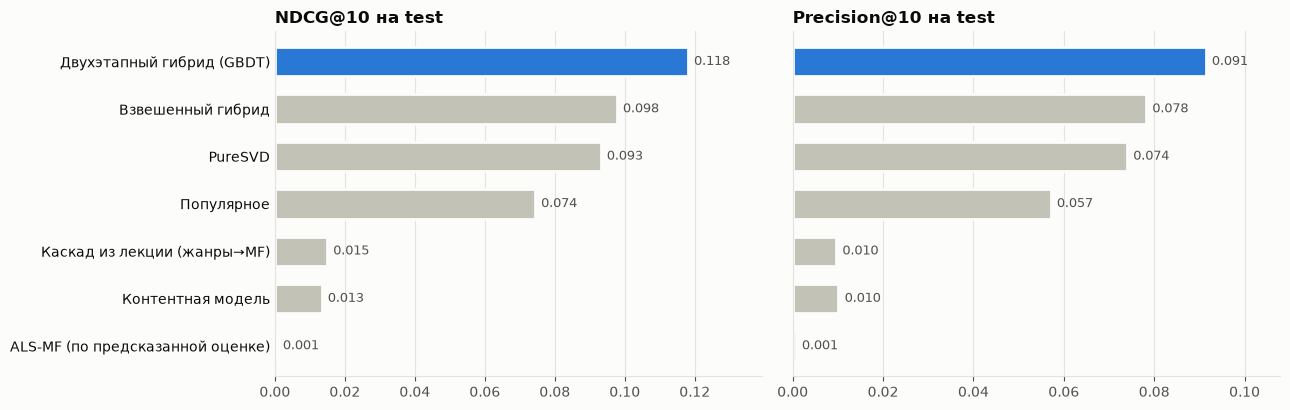

In [21]:
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
C_MAIN, C_WEIGHTED, C_SVD, C_OTHER = '#2a78d6', '#eb6834', '#1baf7a', '#c3c2b7'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK,
                     'text.color': INK, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
order = results.sort_values(f'NDCG@{K}').index
for ax, metric in zip(axes, [f'NDCG@{K}', f'Precision@{K}']):
    vals = results.loc[order, metric]
    colors = [C_MAIN if n == 'Двухэтапный гибрид (GBDT)' else C_OTHER for n in order]
    ax.barh(range(len(order)), vals, height=0.62, color=colors, edgecolor=SURFACE, linewidth=2)
    for y, v in enumerate(vals):
        ax.text(v + vals.max() * 0.015, y, f'{v:.3f}', va='center', fontsize=9, color=INK_2)
    ax.set_yticks(range(len(order)), order)
    ax.set_title(metric + ' на test')
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_xlim(0, vals.max() * 1.18)
    ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'metrics_test.png', dpi=130, bbox_inches='tight')
plt.show()

## 9. Анализ
### 9.1 Пользователи с короткой и длинной историей

,PureSVD,Взвешенный гибрид,Двухэтапный гибрид (GBDT),пользователей
короткая (≤37),0.0840,0.0823,0.1044,202
средняя (38–102),0.0727,0.0718,0.1128,193
длинная (>102),0.1224,0.1388,0.1371,197


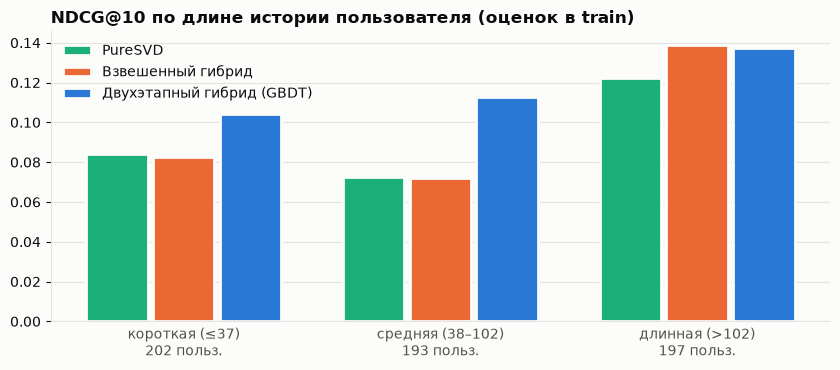

In [22]:
hist_len = pd.Series(np.asarray(seen_B.sum(1)).ravel())[users_B].values
bins = np.quantile(hist_len, [0, 1 / 3, 2 / 3, 1])
labels = [f'короткая (≤{int(bins[1])})', f'средняя ({int(bins[1]) + 1}–{int(bins[2])})', f'длинная (>{int(bins[2])})']
bucket = np.digitize(hist_len, bins[1:-1], right=True)
compare = ['PureSVD', 'Взвешенный гибрид', 'Двухэтапный гибрид (GBDT)']
by_bucket = pd.DataFrame({name: [evaluate(RECS[name][bucket == b], users_B[bucket == b], rel_B, idx.n_items)[f'NDCG@{K}']
                                 for b in range(3)] for name in compare}, index=labels)
by_bucket['пользователей'] = np.bincount(bucket)
display(by_bucket.round(4))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
w = 0.26
for j, (name, col) in enumerate(zip(compare, [C_SVD, C_WEIGHTED, C_MAIN])):
    ax.bar(np.arange(3) + (j - 1) * w, by_bucket[name], width=w - 0.02, color=col, label=name,
           edgecolor=SURFACE, linewidth=2)
ax.set_xticks(range(3), [f'{l}\n{n} польз.' for l, n in zip(labels, by_bucket['пользователей'])])
ax.set_title(f'NDCG@{K} по длине истории пользователя (оценок в train)')
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis='x', length=0)
ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'ndcg_by_history.png', dpi=130, bbox_inches='tight')
plt.show()

### 9.2 «Холодные» фильмы и разнообразие выдачи
Фильмы без единой оценки в `train_full` коллаборативные модели рекомендовать не могут — только контентная часть.

In [23]:
is_cold = np.bincount(train_full['i'], minlength=idx.n_items) == 0
cold_set = set(np.where(is_cold)[0])
rows = []
for name, R in RECS.items():
    top = R[:, :K]
    hits_cold = sum(len(set(r) & rel_B[u] & cold_set) for r, u in zip(top, users_B))
    rows.append({'модель': name, 'доля холодных фильмов в выдаче': is_cold[top].mean(),
                 'попаданий в холодные фильмы': hits_cold, 'Coverage': len(np.unique(top)) / idx.n_items})
pd.DataFrame(rows).set_index('модель').style.format({'доля холодных фильмов в выдаче': '{:.2%}', 'Coverage': '{:.2%}'})

,доля холодных фильмов в выдаче,попаданий в холодные фильмы,Coverage
модель,,,
Популярное,0.00%,0,1.01%
Контентная модель,4.83%,0,13.52%
ALS-MF (по предсказанной оценке),0.00%,0,2.00%
PureSVD,0.00%,0,4.94%
Каскад из лекции (жанры→MF),8.70%,1,18.18%
Взвешенный гибрид,0.00%,0,3.15%
Двухэтапный гибрид (GBDT),0.00%,0,5.50%


### 9.3 Что важно мета-модели
Permutation importance: насколько падает ROC-AUC на `test`, если перемешать признак. Плюс абляция — мета-модель переобучается без группы признаков.

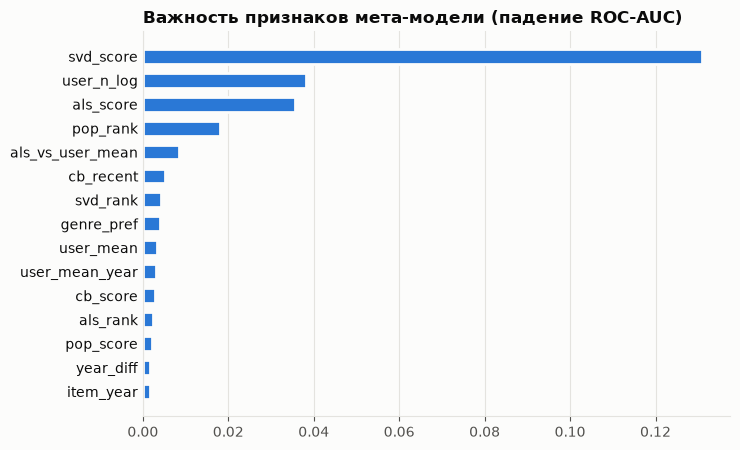

In [24]:
sample = F_B.sample(min(len(F_B), 60_000), random_state=SEED)
pi = permutation_importance(ranker, sample[FEATURES], sample['label'], scoring='roc_auc', n_repeats=3,
                            random_state=SEED)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
top_imp = imp.tail(15)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(range(len(top_imp)), top_imp.values, height=0.62, color=C_MAIN, edgecolor=SURFACE, linewidth=2)
ax.set_yticks(range(len(top_imp)), top_imp.index)
ax.set_title('Важность признаков мета-модели (падение ROC-AUC)')
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'feature_importance.png', dpi=130, bbox_inches='tight')
plt.show()

In [25]:
GROUPS = {
    'без контентных признаков': ['in_cb', 'cb_score', 'cb_rank', 'cb_recent', 'cb_last', 'genre_share',
                                 'genre_pref', 'year_diff'],
    'без ALS (предсказанной оценки)': ['als_score', 'als_rank', 'als_vs_user_mean'],
    'без PureSVD': ['in_svd', 'svd_score', 'svd_rank'],
    'без популярности и статистик фильма': ['in_pop', 'pop_score', 'pop_rank', 'item_n_log', 'item_mean_bayes'],
}
ablation = {'все признаки': results.loc['Двухэтапный гибрид (GBDT)']}
for name, drop in GROUPS.items():
    cols = [c for c in FEATURES if c not in drop]
    m = make_ranker().fit(F_A[cols], F_A['label'])
    p = F_B.assign(p_abl=m.predict_proba(F_B[cols])[:, 1])
    ablation[name] = pd.Series(evaluate(top_from_frame(p, 'p_abl', users_B), users_B, rel_B, idx.n_items))
pd.DataFrame(ablation).T[[f'Precision@{K}', f'Recall@{K}', f'NDCG@{K}', f'HitRate@{K}']].round(4)

,Precision@10,Recall@10,NDCG@10,HitRate@10
все признаки,0.0914,0.0970,0.1180,0.4949
без контентных признаков,0.0801,0.0780,0.1008,0.4409
без ALS (предсказанной оценки),0.0838,0.0831,0.1035,0.4527
без PureSVD,0.0731,0.0724,0.0947,0.4206
без популярности и статистик фильма,0.0878,0.0947,0.1125,0.4916


## 10. Примеры рекомендаций
### 10.1 Существующие пользователи (как `sample_recommendation` в лекции)
✔ — фильм действительно понравился пользователю в тестовом периоде.

In [26]:
title = movies['title'].values


def show_user(user_id, n_known=5):
    u = idx.uid[user_id]
    known = train_full[train_full.u == u].sort_values(['rating', 'timestamp'], ascending=False).head(n_known)
    rec = top_from_frame(F_B[F_B.u == u], 'p', np.array([u]))[0]
    liked_later = rel_B.get(u, set())
    print(f'Пользователь {user_id} (оценок в истории: {seen_B[u].nnz})')
    print('  Любимые фильмы:')
    for row in known.itertuples():
        print(f'      {row.rating:.1f}  {title[int(row.i)]}')
    print('  Рекомендации двухэтапного гибрида:')
    for i in rec:
        print(f'      {"✔" if i in liked_later else " "}  {title[i]}')
    print()


demo_users = [uid for uid in [2, 10, 451] if uid in idx.uid.index and idx.uid[uid] in rel_B]
for uid in demo_users or list(idx.user_ids[users_B[:3]]):
    show_user(uid)

Пользователь 2 (оценок в истории: 23)
  Любимые фильмы:
      5.0  Step Brothers (2008)
      5.0  Wolf of Wall Street, The (2013)
      5.0  The Jinx: The Life and Deaths of Robert Durst (2015)
      4.5  Inglourious Basterds (2009)
      4.5  Dark Knight, The (2008)
  Рекомендации двухэтапного гибрида:
         Up (2009)
         Fight Club (1999)
         Eternal Sunshine of the Spotless Mind (2004)
         Social Network, The (2010)
      ✔  Good Will Hunting (1997)
         Avatar (2009)
         American History X (1998)
         King's Speech, The (2010)
         Bourne Ultimatum, The (2007)
         Lord of the Rings: The Return of the King, The (2003)

Пользователь 10 (оценок в истории: 112)
  Любимые фильмы:
      5.0  Holiday, The (2006)
      5.0  The Intern (2015)
      5.0  Troy (2004)
      5.0  Despicable Me (2010)
      5.0  First Daughter (2004)
  Рекомендации двухэтапного гибрида:
         How to Train Your Dragon (2010)
         Shrek 2 (2004)
         Kung Fu Pand

### 10.2 Новый пользователь (холодный старт, switching)
* история пуста → популярные фильмы с высоким байесовским рейтингом (опционально в выбранных жанрах);
* есть несколько оценок → взвешенный гибрид с fold-in: PureSVD и контентный профиль считаются по введённым оценкам без переобучения.

In [27]:
def find_movie(pattern):
    hit = movies[movies['title'].str.contains(pattern, case=False, regex=False)]
    return int(hit.iloc[0]['movieId'])


def recommend_new_user(user_ratings=None, genres=None, k=K, models=models_B, tr=train_full):
    cnt = np.bincount(tr['i'], minlength=idx.n_items)
    sums = np.bincount(tr['i'], weights=tr['rating'], minlength=idx.n_items)
    bayes = (sums + 10 * tr['rating'].mean()) / (cnt + 10)
    if not user_ratings:                           # пустая история
        score = bayes * np.log1p(cnt)
        if genres:
            ok = movies['genres'].apply(lambda g: all(x in g.split('|') for x in genres)).values
            score = np.where(ok, score, -np.inf)
        return [title[i] for i in np.argsort(-score, kind='stable')[:k]]
    items = idx.iid.loc[list(user_ratings)].values
    r = np.array(list(user_ratings.values()), dtype=float)
    liked = items[r >= REL_THRESHOLD] if (r >= REL_THRESHOLD).any() else items
    s = zscore(models['svd'].fold_in(liked)[None, :])
    s = s + best_w['cb'] * zscore((models['cb'].profile(items, r) @ models['cb'].X.T).toarray())
    s = s + best_w['pop'] * zscore(models['pop'].s[None, :])
    s = s + best_w['als'] * zscore((models['als'].mu + models['als'].bi)[None, :])
    s[0, items] = -np.inf
    return [title[i] for i in topk(s, k)[0]]


print('Пустая история, жанры Sci-Fi:')
for t in recommend_new_user(genres=['Sci-Fi']):
    print('   ', t)

fan = {find_movie('Toy Story (1995)'): 5.0, find_movie('Finding Nemo'): 4.5,
       find_movie('Monsters, Inc.'): 4.5, find_movie('Shining, The'): 2.0}
print('\nНовый пользователь:', ', '.join(f'{title[idx.iid[m]]} — {r}' for m, r in fan.items()))
for t in recommend_new_user(fan):
    print('   ', t)

Пустая история, жанры Sci-Fi:
    Matrix, The (1999)
    Star Wars: Episode IV - A New Hope (1977)
    Star Wars: Episode V - The Empire Strikes Back (1980)
    Star Wars: Episode VI - Return of the Jedi (1983)
    Terminator 2: Judgment Day (1991)
    Jurassic Park (1993)
    Back to the Future (1985)
    Twelve Monkeys (a.k.a. 12 Monkeys) (1995)
    Eternal Sunshine of the Spotless Mind (2004)
    Inception (2010)

Новый пользователь: Toy Story (1995) — 5.0, Finding Nemo (2003) — 4.5, Monsters, Inc. (2001) — 4.5, Shining, The (1980) — 2.0
    Shrek (2001)
    Forrest Gump (1994)
    Lord of the Rings: The Return of the King, The (2003)
    Lord of the Rings: The Two Towers, The (2002)
    Lord of the Rings: The Fellowship of the Ring, The (2001)
    Star Wars: Episode IV - A New Hope (1977)
    Matrix, The (1999)
    Incredibles, The (2004)
    Pirates of the Caribbean: The Curse of the Black Pearl (2003)
    Shawshank Redemption, The (1994)


## 11. Выводы
Цифры — для ml-latest-small, `SEED = 42`, временное разбиение по пользователям, 592 пользователя в test.

1. **Лучший результат — двухэтапный гибрид**: NDCG@10 = 0.118, Precision@10 = 0.091, HitRate@10 = 0.49. Это **+27 % NDCG** к лучшей одиночной модели (PureSVD, 0.093) и +21 % к взвешенному гибриду (0.098). Парный бутстреп по пользователям: 95 % доверительные интервалы разницы не содержат нуля (с PureSVD [+0.014; +0.036], со взвешенным гибридом [+0.009; +0.032]).
2. **Каскад из лекции в честной временной проверке почти не попадает** (NDCG@10 = 0.015, HitRate 8 %): 20 соседей по жанрам последнего фильма — в основном малоизвестные фильмы с тем же жанровым вектором, и переранжирование по MF их не спасает. Тот же сигнал «похож на то, что смотрел недавно» полезен, если подать его мета-модели признаком (`cb_recent`, `cb_last`), а не использовать как жёсткий фильтр.
3. **Хорошая RMSE ≠ хорошие рекомендации.** ALS-MF предсказывает оценки лучше модели смещений (RMSE 0.895 против 0.917), но как самостоятельный рекомендатель бесполезна: 92 % её top-10 — фильмы с 1–2 оценками. В гибриде её предсказание — один из главных признаков: ALS отвечает на вопрос «понравится ли», PureSVD — «будет ли смотреть», а мета-модель объединяет оба ответа.
4. **Где гибрид выигрывает сильнее всего** — у пользователей с короткой и средней историей: 0.104 и 0.113 против 0.084 и 0.073 у PureSVD. У самых активных (>102 оценок) гибрид на уровне простого взвешенного (0.137 против 0.139). Следующий шаг — отдельные мета-модели или признаки по сегментам.
5. **Абляция**: без любой группы признаков NDCG падает; сильнее всего — без PureSVD (0.095), затем без контентных признаков (0.101) и без ALS (0.104), слабее всего — без популярности и статистик фильма (0.113). Надёжно здесь только первое место PureSVD: порядок остальных групп меняется при смене порядка ничьих в кандидатах (в одном из прогонов вклад контента был всего 1–2 %), потому что разброс между запусками (±0.005–0.01 NDCG у мета-модели) сопоставим с этими разницами. Контент в ml-latest-small бедный: 19 жанров, теги есть только у 1.6 тыс. фильмов из 9.7 тыс., поэтому при подборе на valid вес тегов обнулился. В полной ml-latest контентная часть богаче: Tag Genome подключается автоматически.
6. **Холодные фильмы**: 6.6 % понравившихся фильмов в test не имели ни одной оценки в train. Контентная модель рекомендует их (5 % её выдачи), но попаданий почти нет, а мета-модель научилась их избегать. Если новинки нужно продвигать, это решается отдельной квотой в выдаче — продуктовым правилом, а не ранжировщиком.
7. **Холодный старт пользователя** закрыт switching-веткой: пустая история → популярное с байесовским рейтингом по жанрам, несколько оценок → взвешенный гибрид с fold-in, без переобучения моделей.
8. **Воспроизводимость.** У многих фильмов одинаковые векторы признаков, поэтому скоры часто равны. Пока порядок среди равных не был зафиксирован, метрики контентной модели, каскада и (через набор кандидатов) мета-модели менялись от платформы к платформе: NDCG гибрида — от 0.108 до 0.118. После перехода на устойчивую сортировку результат не зависит от числа потоков и повторяется от запуска к запуску; при другой версии библиотек возможны небольшие отклонения. Вывод 1 выполнялся во всех вариантах: гибрид лучше PureSVD, и доверительный интервал не содержит нуля.

**Что можно улучшить:** обучить ранжировщик сразу на порядок (LambdaMART, например `LGBMRanker` из LightGBM) вместо поточечного классификатора; усреднять мета-модель по нескольким сидам, чтобы убрать разброс; добавить генераторы кандидатов (item-kNN, EASE, LightFM с признаками фильмов) — сейчас полнота кандидатов 38 %; подобрать веса холодного старта на пользователях с короткой историей; добавить затухание по времени в профили пользователей.